# EDA текстового датасета Depressive_data

В работе рассматриваются тексты с метками `0` и `1`. Проверяется качество данных, длина сообщений, часто встречающиеся слова и возможные лишние публикации. Метка 1 означает исходную категорию датасета, а не подтверждённый медицинский диагноз.

Используются обычные библиотеки `pandas`, `matplotlib` и `seaborn`. Все графики строятся после запуска ячеек.

## 1.1 Загрузка данных и их проверка

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

# Загружаем CSV с компьютера или через окно Google Colab
try:
    df = pd.read_csv("../../data/Depressive_data/Depressive_data.zip", sep=";", compression="zip")
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)), sep=";")

df.info()
# Первые 20 строк и размер данных
print("Размер таблицы:", df.shape)
print("Столбцы:", df.columns.tolist())
display(df.head(20))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64039 entries, 0 to 64038
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   text    64039 non-null  object 
 1   label   64039 non-null  int64  
 2   age     24325 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 1.5+ MB
Размер таблицы: (64039, 3)
Столбцы: ['text', 'label', 'age']


,text,label,age
0,"Когда-то я был добрым романтиком, который стре...",1,32.0
1,Здраствуйте! Я каждый день просыпаюсь с мыслью...,1,28.0
2,У меня проблемы с девушкой. Каждую ссору я не ...,1,16.0
3,"Вся моя жизнь это один сплошной ад, в котором ...",1,32.0
4,Я хочу уснуть и не проснуться.каждый день одно...,1,14.0
5,Здравствуйте. Я мама ребёнка инвалида 6 лет. З...,1,42.0
6,Я месяц назад начала общатся с иностранцем. Вс...,1,14.0
7,"Начну с начала, у меня есть мама, с ней очень ...",1,18.0
8,Первый и последний раз сходила к косметологу. ...,1,39.0
9,Этот год был очень трудным....,1,17.0


Имеем колонки:


- текст
- lebel (целевая переменная, где 0-нет депрессии, а 1-депрессия)
- age (возраст)

In [2]:
print("Столбцы", df.columns.tolist())
print("Пропуски")
print(df.isna().sum())
print("Повторяющиеся тексты", df["text"].duplicated().sum())
print("Пустые строки", df["text"].fillna("").astype(str).str.strip().eq("").sum())
print("Метки", df["label"].value_counts(dropna=False))

Столбцы ['text', 'label', 'age']
Пропуски
text         0
label        0
age      39714
dtype: int64
Повторяющиеся тексты 0
Пустые строки 1
Метки label
0    32021
1    32018
Name: count, dtype: int64


Датасет содержит 64 039 строк . В столбце age отсутствует 39 714 значений. Полных повторов текстов не обнаруживается.

In [3]:
# Убираем пустые и повторяющиеся тексты
# Короткие сообщения оставляем
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str)
df = df[df["text"].str.strip() != ""]
df = df.drop_duplicates(subset="text").copy()
df = df[df["label"].isin([0, 1])].copy()

df["word_count"] = df["text"].str.split().str.len()
df["char_count"] = df["text"].str.len()
print("Осталось строк", len(df))

Осталось строк 64038


## 1.2 Кол-во сообщений в каждом классе

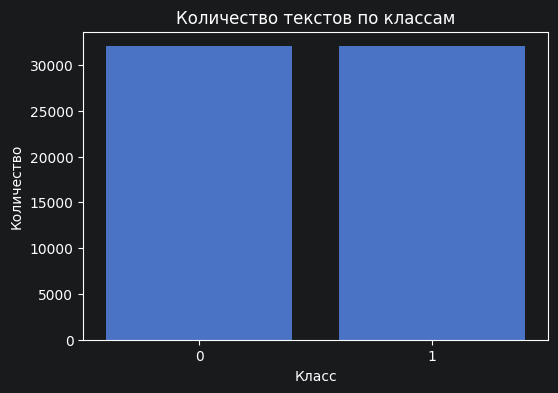

label
0    50.0%
1    50.0%
Name: count, dtype: object


In [4]:
label_counts = df["label"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
sns.barplot(x=label_counts.index.astype(str), y=label_counts.values)
plt.title("Количество текстов по классам")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.show()
print((label_counts / label_counts.sum() * 100).round(1).astype(str) + "%")

Классы распределены почти поровну. Это удобно для обучения модели, но равное количество текстов не означает правильность веток.

## 1.3 Длина сообщений

        mean  median   max
label                     
0      181.5    91.0  2791
1      123.5    69.0  3321


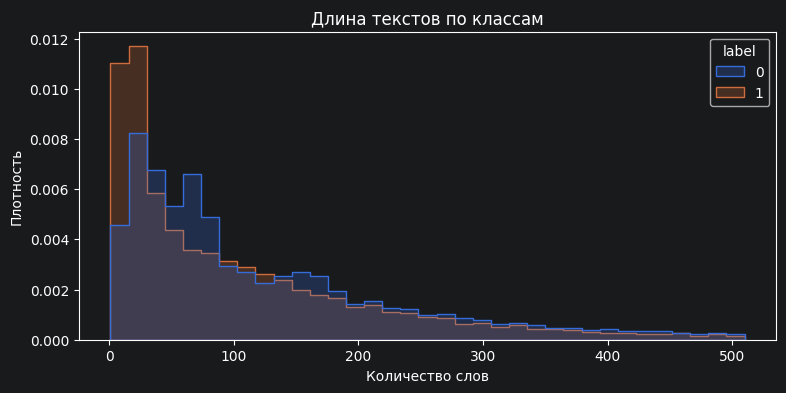

In [5]:
print(df.groupby("label")["word_count"].agg(["mean", "median", "max"]).round(1))

# Ограничиваем ось для графика, а не удаляем длинные сообщения
word_limit = df["word_count"].quantile(0.95)
plt.figure(figsize=(9, 4))
sns.histplot(data=df[df["word_count"] <= word_limit], x="word_count", hue="label", bins=35,
             element="step", stat="density", common_norm=False)
plt.title("Длина текстов по классам")
plt.xlabel("Количество слов")
plt.ylabel("Плотность")
plt.show()

Длина текста класса 0 составляет около 181,5 слова, а класса 1 около 123,5 слова. Сообщения класса 0 в среднем длиннее. Не можем сделать вывод пока не посмотрим содержание текстов.

## 1.4 Сравнение медианной длины и доли коротких текстов

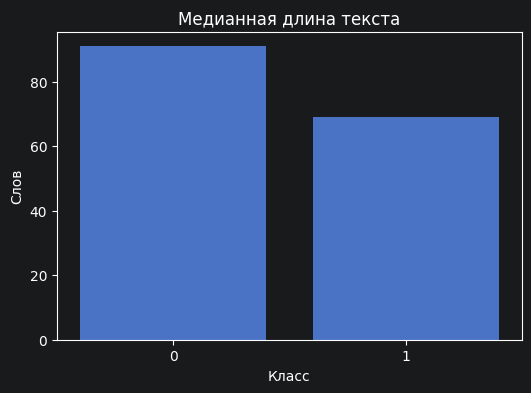

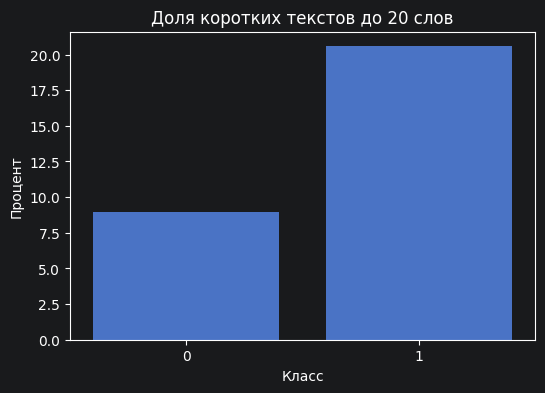

label
0     8.9
1    20.6
Name: short, dtype: float64


In [6]:
median_words = df.groupby("label")["word_count"].median()
short_percent = (df.assign(short=df["word_count"] < 20)
               .groupby("label")["short"].mean() * 100)

plt.figure(figsize=(6, 4))
sns.barplot(x=median_words.index.astype(str), y=median_words.values)
plt.title("Медианная длина текста")
plt.xlabel("Класс")
plt.ylabel("Слов")
plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(x=short_percent.index.astype(str), y=short_percent.values)
plt.title("Доля коротких текстов до 20 слов")
plt.xlabel("Класс")
plt.ylabel("Процент")
plt.show()
print(short_percent.round(1))

## 1.5 Анализ возраста

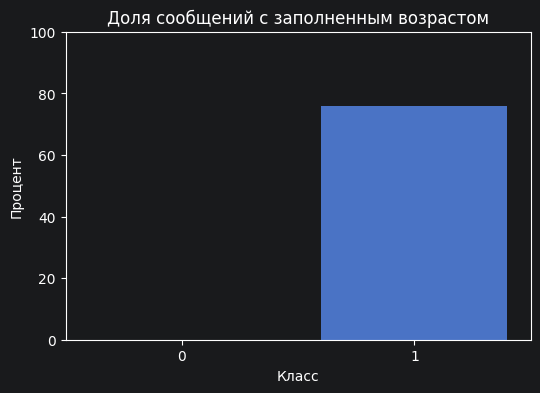

label
0     0.0
1    76.0
Name: age, dtype: float64
Возраст вне диапазона 10–100 111


In [7]:
if "age" in df.columns:
    age_percent = df.groupby("label")["age"].apply(lambda x: x.notna().mean() * 100)
    plt.figure(figsize=(6, 4))
    sns.barplot(x=age_percent.index.astype(str), y=age_percent.values)
    plt.title("Доля сообщений с заполненным возрастом")
    plt.xlabel("Класс")
    plt.ylabel("Процент")
    plt.ylim(0, 100)
    plt.show()
    print(age_percent.round(1))
    print("Возраст вне диапазона 10–100", (~df["age"].between(10, 100) & df["age"].notna()).sum())

Видим что у класса 0 возраст не заполнен. Поэтому по возрасту нельзя корректно сравнивать два класса. Этот столбец также не подходит для обучения модели без дополнительной проверки.

## 1.6 Часто встречающиеся слова

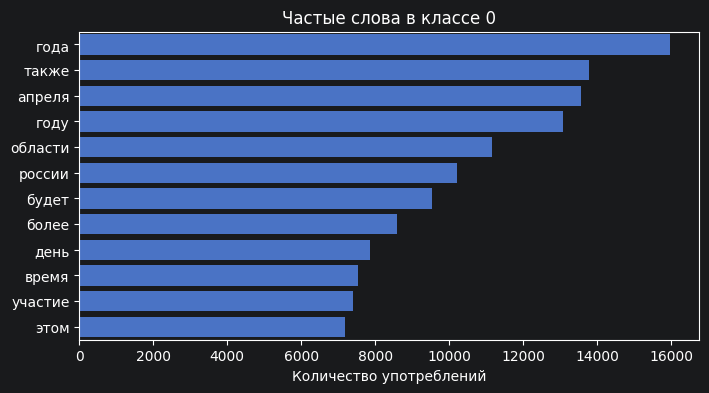

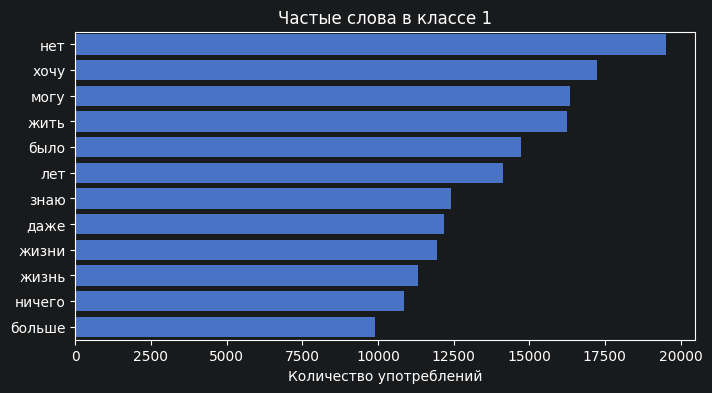

In [8]:
# Небольшой список служебных слов, чтобы не усложнять работу
stop_words = set("и в во на с со к у о об а но что это как я ты мы вы он она они мне меня его ее их для по из от за не ни же ли то так есть был была были быть про при до или если уже еще очень только просто все всё мой моя мое мои себя себе свой свои которого которая которые когда где там тут".split())

def top_words(texts, limit=12):
    all_words = []
    for text in texts:
        words = re.findall(r"[а-яё]{3,}", text.lower())
        all_words.extend([word for word in words if word not in stop_words])
    return Counter(all_words).most_common(limit)

for label in [0, 1]:
    popular_words = top_words(df.loc[df["label"] == label, "text"])
    labels = [word for word, count in popular_words]
    values = [count for word, count in popular_words]
    plt.figure(figsize=(8, 4))
    sns.barplot(x=values, y=labels)
    plt.title(f"Частые слова в классе {label}")
    plt.xlabel("Количество употреблений")
    plt.ylabel("")
    plt.show()

Часто встречающиеся слова позволяют увидеть различия в темах сообщений. При этом частые слова не доказывают наличие депрессии.

## 1.7 Возможные новости, реклама и спам

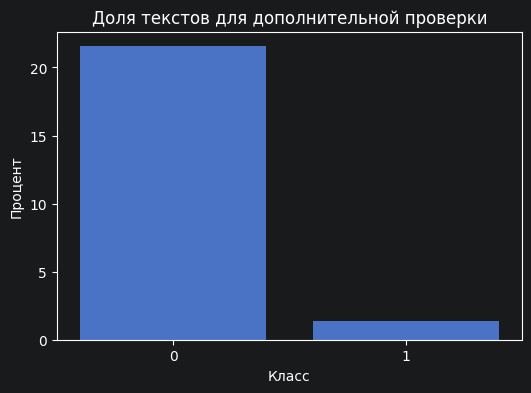

label
0    21.5
1     1.4
Name: needs_check, dtype: float64


,label,text,is_news,is_ad
53,1,У меня небольшой рыбный магазин. В связи с пос...,True,False
57,1,"Пожалуйста , помогите! В мае месяце мы расстал...",False,True
149,1,"не очень хочертся уходить, честно, но просто н...",False,True
159,1,"Мне 31 двое детей, олна воспитываю т к их отец...",False,True
188,1,"Я больше не могу так жить. Мне 32 года, есть д...",False,True
224,1,"Здравствуйте!Я не знаю как рассказать,но мне о...",False,True
237,1,Совсем скоро мне стукнет 18 лет. Сколько бы я ...,False,True
247,1,Простите меня все. Но больше нет сил... долги ...,False,True
260,1,Здравствуйте! Не думала что столкнусь с такой ...,False,True
285,1,Я встречался с девушкой. Мы очень сильно любил...,True,False


In [9]:
# Это только простые признаки для поиска кандидатов на ручную проверку
news_words = r"\b(?:новости|сми|сообщает|сообщили|пресс-служба|по данным|корреспондент|подписывайтесь)\b"
ad_words = r"\b(?:скидка|акция|купить|заказать|доставка|розыгрыш|промокод|реклама|подписывайтесь)\b"

df["is_news"] = df["text"].str.contains(news_words, case=False, regex=True, na=False)
df["is_ad"] = df["text"].str.contains(ad_words, case=False, regex=True, na=False)
df["needs_check"] = df["is_news"] | df["is_ad"]

check_percent = df.groupby("label")["needs_check"].mean() * 100
plt.figure(figsize=(6, 4))
sns.barplot(x=check_percent.index.astype(str), y=check_percent.values)
plt.title("Доля текстов для дополнительной проверки")
plt.xlabel("Класс")
plt.ylabel("Процент")
plt.show()
print(check_percent.round(1))
display(df.loc[df["needs_check"], ["label", "text", "is_news", "is_ad"]].head(15))

Наличие одного слова из списка ещё не означает, что текст является рекламой или новостью. Например, человек может писать о собственных переживаниях и упоминать новости. Поэтому такие сообщения сначала нужно просмотреть вручную.

## 1.8 Отличие классов по типу сообщения

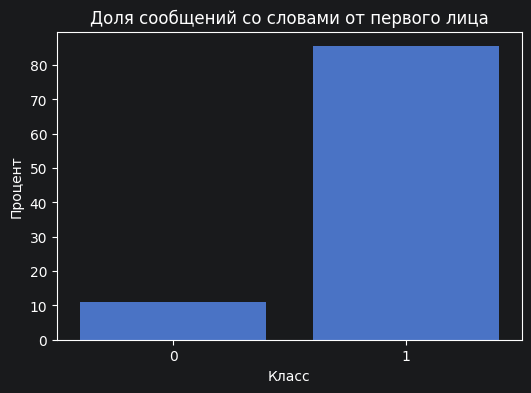

label
0    11.1
1    85.4
Name: has_first_person, dtype: float64


In [10]:
# Дополнительная простая проверка текста от первого лица
first_person = r"\b(?:я|мне|меня|мой|моя|мои|мной)\b"
df["has_first_person"] = df["text"].str.contains(first_person, case=False, regex=True, na=False)
first_person_percent = df.groupby("label")["has_first_person"].mean() * 100
plt.figure(figsize=(6, 4))
sns.barplot(x=first_person_percent.index.astype(str), y=first_person_percent.values)
plt.title("Доля сообщений со словами от первого лица")
plt.xlabel("Класс")
plt.ylabel("Процент")
plt.show()
print(first_person_percent.round(1))

График позволяет посмотреть, не отличается ли класс 1 от класса 0 прежде всего личным стилем повествования. Такой признак нельзя считать доказательством депрессии. Он нужен, чтобы заметить возможную особенность сбора данных и работать с ней далее.

In [11]:
for label in [0, 1]:
    print("Класс", label)
    for text in df.loc[df["label"] == label, "text"].sample(n=3, random_state=42).tolist():
        print(text[:350].replace("\n", " "))
        print()

Класс 0
АвтоВАЗ прекратит экспорт автомобилей Lada в Европу    Российский АвтоВАЗ перестанет продавать автомобили марки Lada в Европе. Об этом корреспонденту Autonews.ru сообщили в пресс-службе компании. В Европе автомобили продавались в таких странах, как Германия, Австрия, Болгария, Литва и Венгрия.    «В связи с ужесточением экологических норм в европей

Россиян научат проводить «Экодворы» для внедрения раздельного сбора мусора  Общероссийский проект «Экодвор» приглашает жителей России организовать в своем дворе экологический праздник, направленный на вовлечение населения в раздельный сбор отходов и практики разумного потребления.  Так, активные жители могут организовать в своем дворе мобильный пун

 на полях Саммита АСЕМ в Брюсселе. Именно тогда вы пригласили меня посетить Казахстан. Я придаю этому визиту очень важное значение, так как в этом году мы отмечаем 10-летие стратегического партнерства между нашими странами, - сказал Мун Чжэ Ин. Президент Южной Кореи особо подчеркнул, что

## Вывод

Датасет содержит тексты двух классов, которые распределены почти поровну. Сообщения класса 0 в среднем длиннее сообщений класса 1. Возраст заполнен неравномерно и содержит некорректные значения, поэтому использовать его для сравнения классов не стоит.

Отдельно выделяются тексты с признаками новостей, рекламы и спама. Их необходимо просмотреть и при необходимости исключить из датасета. Так в выборке останутся сообщения, которые подходят для анализа по смыслу. При этом нейтральные личные тексты важно сохранить, поскольку они помогают модели различать сообщения с депрессивными признаками и без них. Одних ключевых слов для удаления недостаточно.